# Exploration des données (2014 → 2026)

Données chargées avec `charger()` de `dataset_create.py` (colonnes : voir `data/processed_data/README.md`).

In [1]:
import sys; sys.path.append("..") 
import matplotlib.pyplot as plt
import pandas as pd
from dataset_create import charger

df = charger(imputer=True)
AXES = ["Champs-Elysees", "Convention", "Saints-Peres"]
COULEURS = {"Champs-Elysees": "#2a78d6", "Convention": "#eb6834", "Saints-Peres": "#1baf7a"}
print(df.shape)
df.head()

(337464, 23)


,axe,arc_id,debit,occupation,etat_trafic,datetime,impute_debit,impute_occupation,barre,temperature_2m,...,cloud_cover,wind_speed_10m,weather_code,ferie,pont,vacances,paris_respire,evenement,confinement,chantier
0,Champs-Elysees,4264,4.0,0.00000,Fluide,2014-01-01 01:00:00+01:00,False,False,False,5.9,...,10,17.0,0,True,False,Vacances de Noël,False,False,False,0
1,Champs-Elysees,4264,21.0,0.10445,Fluide,2014-01-01 02:00:00+01:00,False,False,False,5.5,...,5,16.3,0,True,False,Vacances de Noël,False,False,False,0
2,Champs-Elysees,4264,417.0,6.12667,Fluide,2014-01-01 03:00:00+01:00,False,False,False,5.2,...,8,17.1,0,True,False,Vacances de Noël,False,False,False,0
3,Champs-Elysees,4264,1089.0,14.39890,Fluide,2014-01-01 04:00:00+01:00,False,False,False,5.0,...,3,16.8,0,True,False,Vacances de Noël,False,False,False,0
4,Champs-Elysees,4264,943.0,10.35220,Fluide,2014-01-01 05:00:00+01:00,False,False,False,4.9,...,13,16.4,0,True,False,Vacances de Noël,False,False,False,0


## Débit journalier sur 12 ans

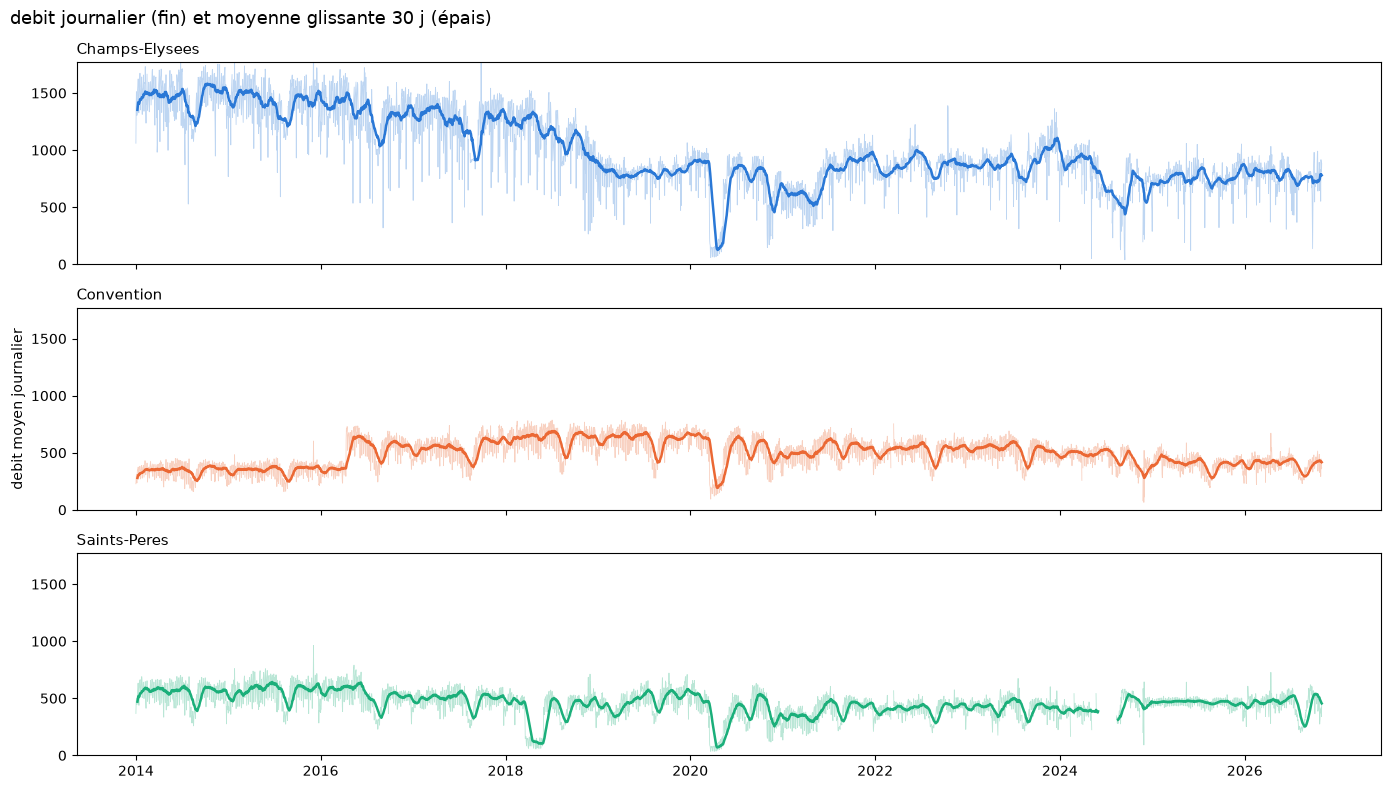

In [2]:
VARIABLE = "debit"

jour = df.groupby(["axe", df["datetime"].dt.date])[VARIABLE].mean().unstack("axe")
jour.index = pd.to_datetime(jour.index)

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True, sharey=True)
for ax, axe in zip(axes, AXES):
    ax.plot(jour.index, jour[axe], color=COULEURS[axe], alpha=0.3, linewidth=0.6)
    ax.plot(jour.index, jour[axe].rolling(30, min_periods=7).mean(), color=COULEURS[axe], linewidth=1.8)
    ax.set_title(axe, loc="left", fontsize=11)
axes[0].set_ylim(0, jour.quantile(0.999).max())  # coupe les pics aberrants
axes[1].set_ylabel(f"{VARIABLE} moyen journalier")
fig.suptitle(f"{VARIABLE} journalier (fin) et moyenne glissante 30 j (épais)", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

## Profil d'une semaine type

Débit moyen par heure de la semaine, sur les 2 dernières années : deux pointes en semaine, un trafic plus tardif le week-end.

C:\Users\Kirat\AppData\Local\Temp\ipykernel_31352\937249495.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  profil = recent.groupby(["axe", recent.datetime.dt.dayofweek * 24 + recent.datetime.dt.hour]).debit.mean().unstack("axe")


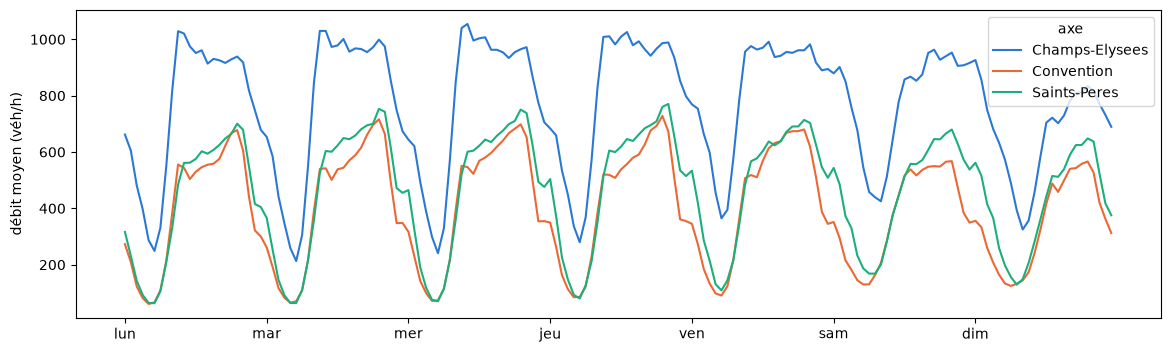

In [4]:
recent = df[df.datetime >= "2024-11-01"]
profil = recent.groupby(["axe", recent.datetime.dt.dayofweek * 24 + recent.datetime.dt.hour]).debit.mean().unstack("axe")

ax = profil[AXES].plot(figsize=(14, 4), color=[COULEURS[a] for a in AXES])
ax.set_xticks(range(0, 168, 24), ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"])
ax.set_xlabel(""); ax.set_ylabel("débit moyen (véh/h)")
plt.show()